In [1]:
import warnings, logging
warnings.filterwarnings("ignore")
logging.disable(logging.WARNING)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from aif360.datasets import AdultDataset
from aif360.metrics import BinaryLabelDatasetMetric, ClassificationMetric
from aif360.algorithms.preprocessing import Reweighing
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
import shap

dataset = AdultDataset()   # sex: 1 = Male (privileged), 0 = Female
privileged   = [{'sex': 1}]
unprivileged = [{'sex': 0}]

metric = BinaryLabelDatasetMetric(dataset,
            unprivileged_groups=unprivileged,
            privileged_groups=privileged)
print("Disparate Impact:", metric.disparate_impact())
print("Statistical Parity Diff:", metric.statistical_parity_difference())

Disparate Impact: 0.3634695423643793
Statistical Parity Diff: -0.198901432678815


In [2]:
dataset = AdultDataset()
privileged   = [{'sex': 1}]   # Male
unprivileged = [{'sex': 0}]   # Female
print(dataset.feature_names)

['age', 'education-num', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'workclass=Federal-gov', 'workclass=Local-gov', 'workclass=Private', 'workclass=Self-emp-inc', 'workclass=Self-emp-not-inc', 'workclass=State-gov', 'workclass=Without-pay', 'education=10th', 'education=11th', 'education=12th', 'education=1st-4th', 'education=5th-6th', 'education=7th-8th', 'education=9th', 'education=Assoc-acdm', 'education=Assoc-voc', 'education=Bachelors', 'education=Doctorate', 'education=HS-grad', 'education=Masters', 'education=Preschool', 'education=Prof-school', 'education=Some-college', 'marital-status=Divorced', 'marital-status=Married-AF-spouse', 'marital-status=Married-civ-spouse', 'marital-status=Married-spouse-absent', 'marital-status=Never-married', 'marital-status=Separated', 'marital-status=Widowed', 'occupation=Adm-clerical', 'occupation=Armed-Forces', 'occupation=Craft-repair', 'occupation=Exec-managerial', 'occupation=Farming-fishing', 'occupation=Handlers-cleane

In [3]:
metric = BinaryLabelDatasetMetric(dataset,
            unprivileged_groups=unprivileged,
            privileged_groups=privileged)
di_original = metric.disparate_impact()
spd_original = metric.statistical_parity_difference()
print("Disparate Impact:", di_original)
print("Statistical Parity Difference:", spd_original)
print("Below 0.8 = potential bias:", di_original < 0.8)

Disparate Impact: 0.3634695423643793
Statistical Parity Difference: -0.198901432678815
Below 0.8 = potential bias: True


In [4]:
train, test = dataset.split([0.7], shuffle=True, seed=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(train.features)
X_test  = scaler.transform(test.features)
y_train = train.labels.ravel()
y_test  = test.labels.ravel()

X_train_df = pd.DataFrame(X_train, columns=dataset.feature_names)
X_test_df  = pd.DataFrame(X_test,  columns=dataset.feature_names)

In [5]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
print("Accuracy:", model.score(X_test, y_test))

Accuracy: 0.8462445640156262


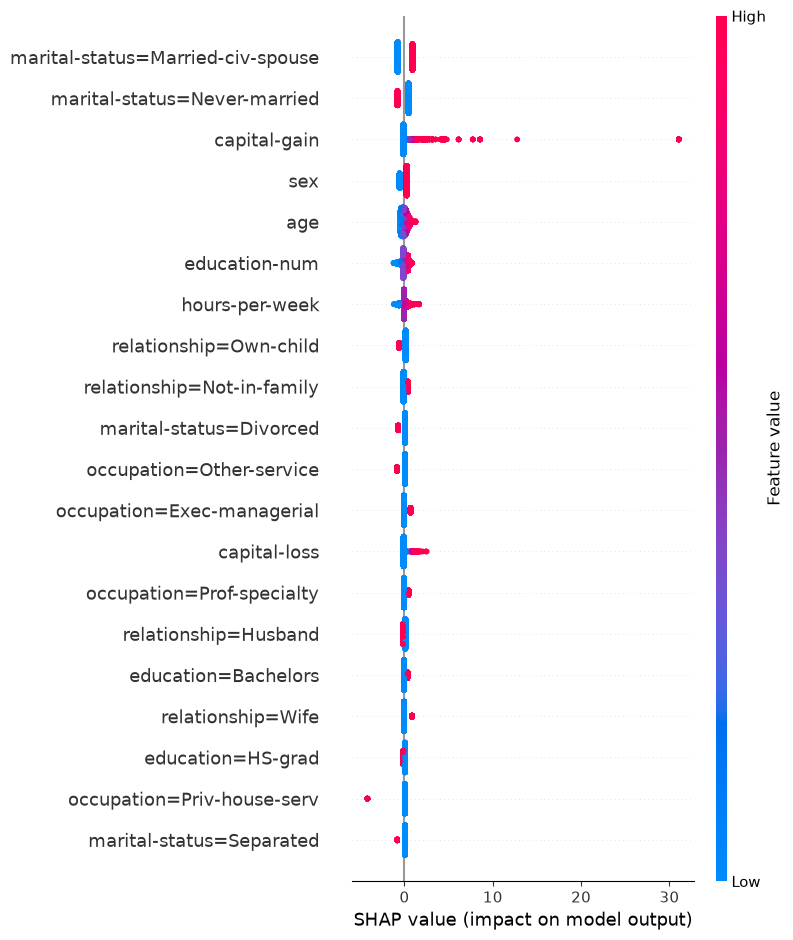

In [6]:
explainer = shap.LinearExplainer(model, X_train_df)
shap_values = explainer(X_test_df)

shap.summary_plot(shap_values.values, X_test_df, show=False)
plt.savefig("shap_summary.png", bbox_inches="tight", dpi=150)
plt.show()

In [7]:
importance = pd.Series(np.abs(shap_values.values).mean(axis=0),
                       index=dataset.feature_names).sort_values(ascending=False)
print(importance.head(10))
print("Rank of sex:", list(importance.index).index('sex') + 1)

marital-status=Married-civ-spouse    0.834022
marital-status=Never-married         0.570447
capital-gain                         0.461307
sex                                  0.347938
age                                  0.261333
education-num                        0.252143
hours-per-week                       0.233305
relationship=Own-child               0.208604
relationship=Not-in-family           0.173235
marital-status=Divorced              0.170418
dtype: float64
Rank of sex: 4


In [8]:
metric_train = BinaryLabelDatasetMetric(train,
                unprivileged_groups=unprivileged, privileged_groups=privileged)

RW = Reweighing(unprivileged_groups=unprivileged, privileged_groups=privileged)
train_rw = RW.fit_transform(train)

metric_rw = BinaryLabelDatasetMetric(train_rw,
                unprivileged_groups=unprivileged, privileged_groups=privileged)

print("Train DI before:", metric_train.disparate_impact())
print("Train DI after :", metric_rw.disparate_impact())

Train DI before: 0.35185542549642124
Train DI after : 1.0000000000000002


In [9]:
def evaluate(m):
    pred = test.copy()
    pred.labels = m.predict(X_test).reshape(-1, 1)
    cm = ClassificationMetric(test, pred,
            unprivileged_groups=unprivileged, privileged_groups=privileged)
    return {"Accuracy": cm.accuracy(),
            "Disparate Impact": cm.disparate_impact(),
            "Stat Parity Diff": cm.statistical_parity_difference(),
            "Avg Odds Diff": cm.average_odds_difference()}

In [10]:
model_rw = LogisticRegression(max_iter=1000)
model_rw.fit(X_train, y_train, sample_weight=train_rw.instance_weights.ravel())

results = pd.DataFrame({"Before (original)": evaluate(model),
                        "After (reweighed)": evaluate(model_rw)}).round(3)
results

,Before (original),After (reweighed)
Accuracy,0.846,0.840
Disparate Impact,0.316,0.642
Stat Parity Diff,-0.183,-0.077
Avg Odds Diff,-0.093,0.085


In [11]:
print(results.to_markdown())

|                  |   Before (original) |   After (reweighed) |
|:-----------------|--------------------:|--------------------:|
| Accuracy         |               0.846 |               0.84  |
| Disparate Impact |               0.316 |               0.642 |
| Stat Parity Diff |              -0.183 |              -0.077 |
| Avg Odds Diff    |              -0.093 |               0.085 |


**Findings**
- Original dataset DI = 0.363 (< 0.8), so there is gender bias against women.
- `sex` ranks 4th in SHAP feature importance.
- Reweighing raised test DI from 0.316 to 0.642 and cut SPD from -0.183 to -0.077, at a cost of 0.6 points of accuracy.
- DI is still below 0.8, so reweighing alone is not enough.

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import textwrap
import matplotlib.image as mpimg

fig = plt.figure(figsize=(8.27, 11.69))   # A4
y = 0.965
LEFT = 0.07

def put(text, size=9, bold=False, wrap=105, gap=0.0):
    global y
    for line in textwrap.wrap(text, wrap):
        fig.text(LEFT, y, line, fontsize=size,
                 fontweight="bold" if bold else "normal", va="top")
        y -= size * 1.5 / 72 / 11.69
    y -= gap

put("Model Card: Income Prediction (Logistic Regression)", 15, True, 70, 0.004)
put("Name: Adult Income Classifier v1  |  Date: 26 Nov 2026  |  Author: Chaithanya Pasupuleti", 8.5, False, 120, 0.012)

sections = [
 ("Model Details", "Logistic Regression (scikit-learn), plus a Reweighing-mitigated variant."),
 ("Intended Use", "Learning exercise on bias auditing. Not for real hiring, lending or credit decisions."),
 ("Factors", "Gender (audited: male = privileged, female = unprivileged). Race and age are model features but were not audited."),
 ("Metrics", "Accuracy, Disparate Impact (DI), Statistical Parity Difference (SPD), Average Odds Difference (AOD)."),
 ("Evaluation and Training Data", "UCI Adult Income (1994 US Census), 70/30 train/test split (seed 42). 3,620 rows with missing values were removed. Original dataset DI by gender = 0.363."),
 ("Ethical Considerations", "- Raw data DI of 0.363 fails the four-fifths rule (0.8). Reweighing improved test DI to 0.642, still below 0.8.\n- Marital status and relationship features likely act as proxies for gender."),
 ("Caveats", "- 1994 US data, not valid for Indian populations or current conditions.\n- Only gender was audited, using DI, SPD and AOD. Only Reweighing was tried.\n- Not suitable for production use."),
 ("Quantitative Analyses", "Before vs after Reweighing on the test set. 'sex' ranks 4th in SHAP importance, after marital status and capital gain."),
]
for head, body in sections:
    put(head, 11, True, 100, 0.002)
    for part in body.split("\n"):
        put(part, 9, False, 105)
    y -= 0.010

# table (bottom-left)
ax_t = fig.add_axes([LEFT, 0.06, 0.45, 0.18]); ax_t.axis("off")
cells = [["Accuracy", "0.846", "0.840"],
         ["Disparate Impact", "0.316", "0.642"],
         ["Stat Parity Diff", "-0.183", "-0.077"],
         ["Avg Odds Diff", "-0.093", "0.085"]]
tb = ax_t.table(cellText=cells, colLabels=["Metric", "Before", "After Reweighing"],
                loc="upper left", cellLoc="left")
tb.auto_set_font_size(False); tb.set_fontsize(9); tb.scale(1.15, 1.6)

# SHAP image (bottom-right)
img = mpimg.imread("shap_summary.png")
w_in = 3.0; h_in = w_in * img.shape[0] / img.shape[1]
ax_i = fig.add_axes([0.55, 0.03, w_in / 8.27, h_in / 11.69]); ax_i.axis("off")
ax_i.imshow(img)

print("Text ends at y =", round(y, 3), "| image top at y =", round(0.03 + h_in / 11.69, 3))
fig.savefig("model_card.pdf")
plt.close(fig)

Text ends at y = 0.414 | image top at y = 0.332


In [12]:
import os, ssl, urllib.request

folder = r"c:\Users\Sateesh\ai-ml-internship\venv\Lib\site-packages\aif360\data\raw\adult"
os.makedirs(folder, exist_ok=True)
base = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/"

ctx = ssl.create_default_context()
ctx.check_hostname = False
ctx.verify_mode = ssl.CERT_NONE

for f in ["adult.data", "adult.test", "adult.names"]:
    with urllib.request.urlopen(base + f, context=ctx) as r, open(os.path.join(folder, f), "wb") as out:
        out.write(r.read())
    print("downloaded", f)

downloaded adult.data
downloaded adult.test
downloaded adult.names


In [13]:
import pandas as pd; print(pd.__version__)

2.3.3


In [14]:
import sys, pandas as pd
print(sys.executable)
print(pd.__version__)

c:\Users\Sateesh\ai-ml-internship\venv\Scripts\python.exe
2.3.3
